# 01 — City Listings EDA: does size or location drive nightly price?

**TL;DR.** Using 20,320 New York City Airbnb listings with a usable nightly price, I compared a
size-only model, a location-only model, and a model with both. Location explains slightly more on
its own (5-fold CV R² 0.265 vs 0.234), but the two are complementary: together they reach
**CV R² 0.469**, and adding location to a size + room-type model lifts R² by **+0.175**. In plain
terms, size sets the baseline price of a listing; neighbourhood sets the multiplier on top of it.
The final model explains about half of the variation in log price (holdout R² 0.498, MAE $92), which
is a useful signal but nowhere near a pricing oracle.

*Portfolio project 01 of 07 · EDA, missing-data judgement, linear regression, cross-validation.*

## 1. What this notebook does

This is an exploratory analysis with a small modelling section at the end. It is organised as:

1. **The question** and why a data team would care.
2. **The data**: where it comes from, what one row means, and what is missing.
3. **Cleaning**: every filter is a decision, so I record the decision and its cost.
4. **EDA**: price distributions, the size relationship, the location pattern, and correlations.
5. **Modelling**: a median baseline, then size-only, location-only, and combined models.
6. **Evaluation and interpretation**: what the metrics mean in dollars and in plain language.
7. **Limitations** and what I would do next.

I wrote the notebook to be readable on its own. If you only want the answer, the TL;DR above and
Section 8 are enough; the rest shows the work.

## 2. The question, and why it matters

A host, an investor, or a marketplace team all face a version of the same question: **what makes one
listing worth more per night than another?** Two competing explanations are easy to state:

- **Size**: bigger places sleep more people, so they command more. A two-bedroom should beat a
  studio.
- **Location**: the same apartment is worth more in Manhattan than in the Bronx. Buyers pay for
  access to jobs, transit, and amenities.

In practice both matter, but they matter in different ways and to different degrees. That matters
for decisions:

- A host deciding whether to add a bedroom or move to a better neighbourhood needs to know which
  lever moves price more.
- A marketplace ranking listings needs a price expectation that separates "expensive because it is
  big" from "expensive because it is in SoHo".
- An analyst doing fairness or anomaly checks needs to know how much of a price gap is explained by
  observable characteristics before calling something suspicious.

The question is deliberately narrow. I am **not** trying to build a production pricing model, and I
am **not** claiming causality. I am asking how much of the variation in asking prices is associated
with size versus location, using a transparent model that I can explain line by line.

## 3. Data

**Source:** [Inside Airbnb](https://insideairbnb.com/get-the-data/), New York City snapshot
`2026-06-14`, file `listings.csv.gz`. Inside Airbnb publishes scrapes of Airbnb listings for
research and advocacy; it is not an official Airbnb feed.

**Licence:** Inside Airbnb's [data policies](https://insideairbnb.com/data-policies/) apply. The
dataset is **not committed** to this repository; `data/` is git-ignored. Download the gzipped CSV
from the link above into `data/` to reproduce this notebook.

**What one row is:** one *listing*, not one booking and not one night. The price is the advertised
nightly price at scrape time, not the price anyone actually paid. That distinction matters for every
conclusion below.

**Size:** 30,259 rows and 90 columns in this snapshot. The columns cover the listing (room type,
property type, capacity, bedrooms, price), the host (response rate, superhost status, listing
count), reviews, availability, and a few fields derived from a price quote.

**Known quirks before I touch anything:**

- `price` is a formatted string (`"$1,200.00"`), not a number.
- About 29% of listings have no `price` at all.
- `bedrooms`, `beds`, and `bathrooms` are missing for roughly a third of listings.
- `minimum_nights` has a median of 30 days, which is unusually high and suggests many listings are
  aimed at medium-term stays rather than tourists.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

NAVY, TEAL, ORANGE, GOLD, GRAY = "#12355B", "#1B998B", "#E07A5F", "#F2CC8F", "#6B7280"

## 4. Load and first look

I keep the raw frame untouched and build a cleaned copy later. That way every cleaning step can be
measured against the original, and I can still answer questions like "how many rows did that filter
remove?" without re-reading the file.

In [2]:
DATA = Path("data/listings.csv.gz")
if not DATA.exists():
    raise FileNotFoundError(
        "Missing data/listings.csv.gz. Download the NYC snapshot from "
        "https://insideairbnb.com/get-the-data/ and place it in data/."
    )

raw = pd.read_csv(DATA, low_memory=False)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

raw[[
    "id", "neighbourhood_group_cleansed", "neighbourhood_cleansed",
    "room_type", "price", "accommodates", "bedrooms", "beds",
    "bathrooms", "minimum_nights",
]].head()

30,259 rows x 90 columns


,id,neighbourhood_group_cleansed,neighbourhood_cleansed,room_type,price,accommodates,bedrooms,beds,bathrooms,minimum_nights
0,2539,Brooklyn,Kensington,Private room,$113.97,2,1.00,2.00,1.00,30.00
1,6848,Brooklyn,Williamsburg,Entire home/apt,$117.27,3,2.00,1.00,1.00,30.00
2,6872,Manhattan,East Harlem,Private room,$80.06,1,NaN,1.00,1.00,30.00
3,6990,Manhattan,East Harlem,Private room,$77.17,1,NaN,1.00,1.00,30.00
4,7097,Brooklyn,Fort Greene,Private room,$202.47,2,NaN,2.00,1.00,30.00


The first five rows already show the shape of the problem. The price column is text, and the
neighbourhood columns are nested: `neighbourhood_group_cleansed` is the borough (Manhattan,
Brooklyn, Queens, Bronx, Staten Island), while `neighbourhood_cleansed` is the finer neighbourhood
(SoHo, Williamsburg, Astoria, …). I will use both: the borough for readable summaries, and the
neighbourhood for the model's location signal.

### 4.1 Parse price and audit missingness

Before deciding what to do with missing values, I want to know whether they are random. A column
that is missing at random can be dropped or imputed with limited damage. A column that is missing
*systematically* — for example, because a certain kind of host hides prices — changes who the
analysis is about.

In [3]:
price = pd.to_numeric(
    raw["price"].astype(str).str.replace(r"[\$,]", "", regex=True),
    errors="coerce",
)

audit = pd.DataFrame({
    "missing_count": [
        price.isna().sum(),
        raw["bedrooms"].isna().sum(),
        raw["beds"].isna().sum(),
        raw["bathrooms"].isna().sum(),
        raw["review_scores_rating"].isna().sum(),
        raw["host_response_rate"].isna().sum(),
    ],
    "missing_pct": [
        price.isna().mean(),
        raw["bedrooms"].isna().mean(),
        raw["beds"].isna().mean(),
        raw["bathrooms"].isna().mean(),
        raw["review_scores_rating"].isna().mean(),
        raw["host_response_rate"].isna().mean(),
    ],
}, index=["price", "bedrooms", "beds", "bathrooms", "review_scores_rating", "host_response_rate"])
audit["missing_pct"] = audit["missing_pct"].map(lambda x: f"{x:.1%}")
audit

,missing_count,missing_pct
price,8744,28.9%
bedrooms,10973,36.3%
beds,9420,31.1%
bathrooms,10112,33.4%
review_scores_rating,8559,28.3%
host_response_rate,30259,100.0%


### 4.2 Missing price is not random

The missing-price rate is about 29% overall, but it is not spread evenly. It is higher in Brooklyn
and Manhattan than in the Bronx or Staten Island, and higher for entire homes than for hotel rooms.
That pattern matters: if I simply drop missing prices, the remaining sample over-represents some
boroughs and room types relative to the full marketplace. Every result below therefore describes
**listings with a visible price**, not all NYC listings.

I plot the missingness by borough and room type rather than only quoting one number, because the
pattern is the interesting part.

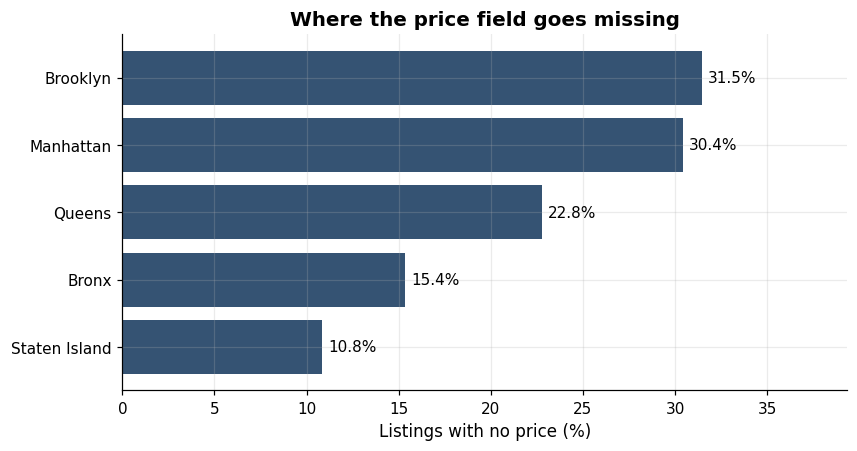

In [4]:
price_by_group = (
    raw.assign(price=price)
       .groupby("neighbourhood_group_cleansed")["price"]
       .apply(lambda s: s.isna().mean())
       .sort_values()
)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.barh(price_by_group.index, price_by_group.values * 100, color=NAVY, alpha=0.85)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10)
ax.set_xlabel("Listings with no price (%)")
ax.set_title("Where the price field goes missing")
ax.set_xlim(0, price_by_group.max() * 100 * 1.25)
plt.show()

A missing price does not mean a listing is inactive; it may mean the host has not published a
nightly rate, the listing is quote-only, or the scraper could not capture it. Whatever the cause, I
cannot recover it from this file, and I should not pretend the remaining rows are a random sample.
I will carry that caveat through to the interpretation.

## 5. Cleaning decisions

I make four decisions, each with a reason and a cost:

1. **Drop rows without a price.** They cannot contribute to a price analysis. *Cost:* the sample
   shifts toward listings with visible prices (Section 4.2).
2. **Keep prices between $20 and $1,000 per night.** Below $20 is almost certainly a data error or
   a shared-room anomaly; above $1,000 is a tiny, high-leverage tail that would dominate a linear
   model. The $1,000 cut is roughly the 97th percentile of the raw price distribution. *Cost:* I
   lose genuinely expensive listings, so the model is not calibrated for the luxury segment.
3. **Keep listings with `minimum_nights <= 30`.** Listings above a 30-night minimum are often
   medium-term rentals and their nightly price is not comparable to a short stay. The median is
   exactly 30, so this rule keeps the median listing and trims the longer-stay tail; after the price
   band it removes 535 rows (2.6%). *Cost:* results apply to short-stay listings, not the whole
   platform.
4. **Do not impute the target.** Imputing price would invent the very quantity I am trying to
   explain.

I deliberately do **not** drop rows missing `bedrooms`, `beds`, or `bathrooms`. Instead, the model
imputes them with the median inside each cross-validation fold. Dropping them would remove about a
third of the sample and bias it toward fully specified listings.

In [5]:
clean = raw.assign(price=price).dropna(subset=["price"])
n_raw = len(raw)
n_priced = len(clean)

clean = clean[clean["price"].between(20, 1000)]
n_price_band = len(clean)

clean = clean[clean["minimum_nights"] <= 30]
n_short_stay = len(clean)

clean = clean.copy()
clean["log_price"] = np.log(clean["price"])

funnel = pd.DataFrame({
    "rows": [n_raw, n_priced, n_price_band, n_short_stay],
    "removed": [0, n_raw - n_priced, n_priced - n_price_band, n_price_band - n_short_stay],
}, index=[
    "Raw listings",
    "With a price",
    "Price $20–$1,000",
    "Minimum nights ≤ 30",
])
funnel["share_of_raw"] = (funnel["rows"] / n_raw).map(lambda x: f"{x:.1%}")
funnel

,rows,removed,share_of_raw
Raw listings,30259,0,100.0%
With a price,21515,8744,71.1%
"Price $20–$1,000",20855,660,68.9%
Minimum nights ≤ 30,20320,535,67.2%


The final sample is **20,320 listings**, about two-thirds of the raw file. That is large enough for
the comparisons I want, but the funnel is a reminder that this is a *filtered* view of the market.
If the missing prices belonged disproportionately to budget listings, the median I report below
would be too high. I cannot test that with this file alone.

In [6]:
print(f"Median nightly price: ${clean['price'].median():,.2f}")
print(f"Mean nightly price:   ${clean['price'].mean():,.2f}")
print(f"Std. dev.:            ${clean['price'].std():,.2f}")
print(f"90th percentile:      ${clean['price'].quantile(0.90):,.2f}")
print(f"99th percentile:      ${clean['price'].quantile(0.99):,.2f}")

Median nightly price: $171.83
Mean nightly price:   $225.38
Std. dev.:            $177.40
90th percentile:      $467.36
99th percentile:      $868.41


## 6. Exploratory analysis

### 6.1 Price is skewed, so I model the log

The mean is well above the median, which is the signature of a right-skewed distribution: a small
number of expensive listings pull the average up. A linear model fitted to raw price would spend
most of its effort fitting those few expensive rows and would fit the typical listing poorly.

Taking `log(price)` changes the question slightly — the model predicts *multiplicative* differences
(a 10% increase) rather than additive ones (a $50 increase). That is usually what pricing data wants:
a $100 upgrade means something different for a $80 room than for a $500 apartment. I will evaluate
on the log scale for model comparison and convert back to dollars for the plain-language metrics.

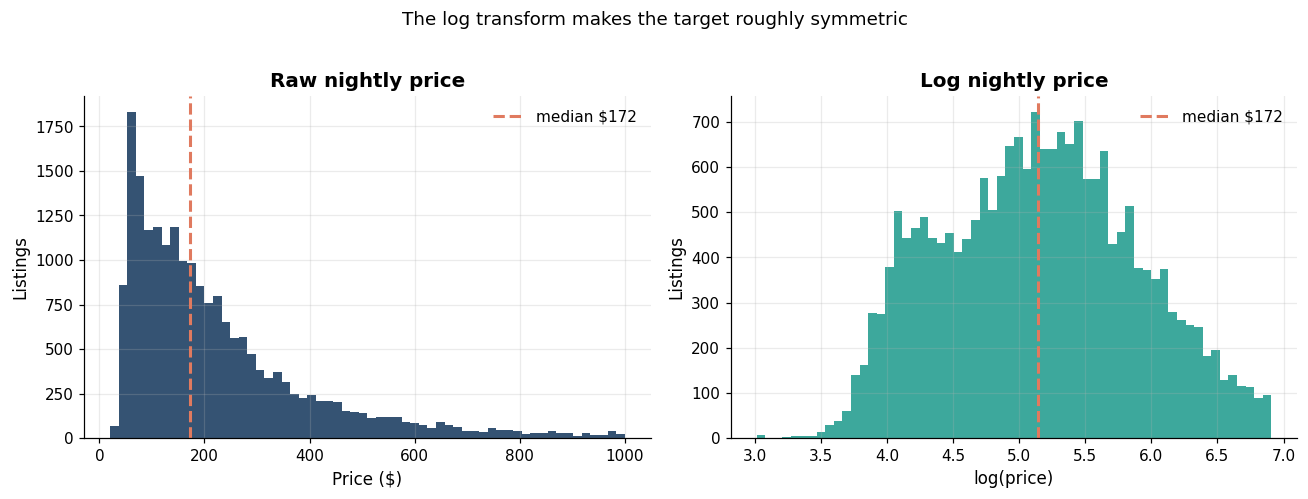

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].hist(clean["price"], bins=60, color=NAVY, alpha=0.85)
axes[0].axvline(clean["price"].median(), color=ORANGE, lw=2, ls="--",
                label=f"median ${clean['price'].median():,.0f}")
axes[0].set_title("Raw nightly price")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Listings")
axes[0].legend(frameon=False)

axes[1].hist(clean["log_price"], bins=60, color=TEAL, alpha=0.85)
axes[1].axvline(clean["log_price"].median(), color=ORANGE, lw=2, ls="--",
                label=f"median ${clean['price'].median():,.0f}")
axes[1].set_title("Log nightly price")
axes[1].set_xlabel("log(price)")
axes[1].set_ylabel("Listings")
axes[1].legend(frameon=False)

fig.suptitle("The log transform makes the target roughly symmetric", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

The raw distribution has a long right tail; the log version is much closer to a bell shape. The
remaining bump near the low end is mostly private and shared rooms. A symmetric target is not a
requirement for linear regression, but it makes the model's errors easier to interpret and reduces
the influence of a handful of luxury listings.

### 6.2 Price by borough and room type

Two categorical variables are likely to matter immediately: **where** the listing is and **what kind
of space** it is. I look at them separately before combining them, because they are correlated —
entire homes are more common in some boroughs, and private rooms in others. If I only look at one, I
risk attributing the other's effect to it.

In [8]:
borough_stats = (
    clean.groupby("neighbourhood_group_cleansed")["price"]
         .agg(["size", "median", "mean"])
         .sort_values("median")
         .rename(columns={"size": "listings", "median": "median_price", "mean": "mean_price"})
)
borough_stats

,listings,median_price,mean_price
neighbourhood_group_cleansed,,,
Bronx,807,106.57,131.97
Staten Island,282,107.78,135.65
Queens,3500,120.15,156.39
Brooklyn,6960,151.50,195.92
Manhattan,8771,234.78,287.77


In [9]:
room_stats = (
    clean.groupby("room_type")["price"]
         .agg(["size", "median", "mean"])
         .sort_values("median")
         .rename(columns={"size": "listings", "median": "median_price", "mean": "mean_price"})
)
room_stats

,listings,median_price,mean_price
room_type,,,
Shared room,184,52.21,126.64
Private room,8974,102.05,158.68
Entire home/apt,10747,221.27,274.28
Hotel room,415,399.00,445.29


The borough gap is large: the median Manhattan listing is about **$235** per night, roughly 2.2×
the Bronx median of **$107**. The room-type gap is just as large: an entire home or apartment
medians **$221**, a private room **$102**. These two gaps overlap — Manhattan has a higher share of
entire homes — which is exactly why the model needs both variables at once.

Hotel rooms are the most expensive median, but there are only 415 of them; I keep them because the
model can use the category, but I will not over-interpret a small group.

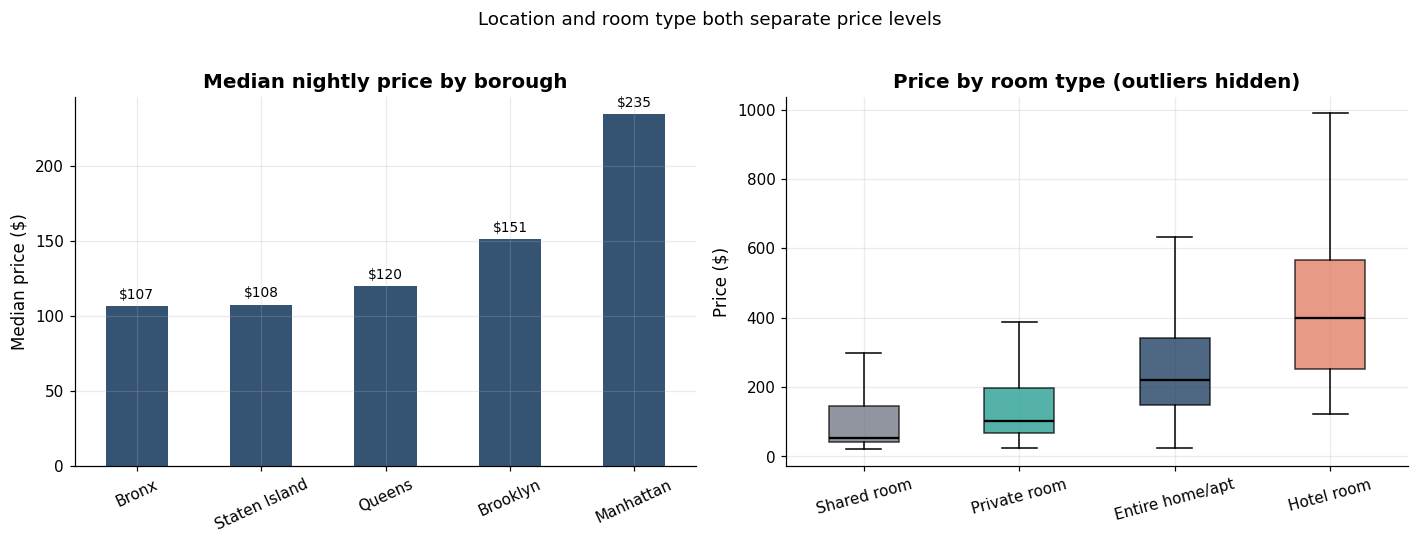

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

borough_stats["median_price"].plot(kind="bar", ax=axes[0], color=NAVY, alpha=0.85)
axes[0].set_title("Median nightly price by borough")
axes[0].set_ylabel("Median price ($)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(borough_stats["median_price"]):
    axes[0].text(i, v + 5, f"${v:,.0f}", ha="center", fontsize=9)

order = ["Shared room", "Private room", "Entire home/apt", "Hotel room"]
data = [clean.loc[clean["room_type"] == r, "price"] for r in order]
bp = axes[1].boxplot(data, patch_artist=True, showfliers=False,
                     medianprops={"color": "black", "linewidth": 1.5})
for patch, color in zip(bp["boxes"], [GRAY, TEAL, NAVY, ORANGE]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
axes[1].set_xticks(range(1, len(order) + 1))
axes[1].set_xticklabels(order)
axes[1].set_title("Price by room type (outliers hidden)")
axes[1].set_ylabel("Price ($)")
axes[1].tick_params(axis="x", rotation=15)

fig.suptitle("Location and room type both separate price levels", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

The bar chart makes the borough ranking obvious, but it hides a confound: the median within a
borough mixes room types. The box plot shows that the room-type difference is not just a few
outliers — the entire box shifts. A shared room tops out around the bottom of an entire-home box.

### 6.3 Size: more guests, more money, with diminishing returns

Size is not one variable. `accommodates` (how many guests the listing sleeps) is the broadest
measure, but `bedrooms`, `beds`, and `bathrooms` are related and partly redundant. I use
`accommodates` for the visual because it is the cleanest and least missing, and keep the other three
for the model.

The relationship is positive but not linear in dollars. On a log scale it looks much closer to a
straight line, which is another reason to model log price.

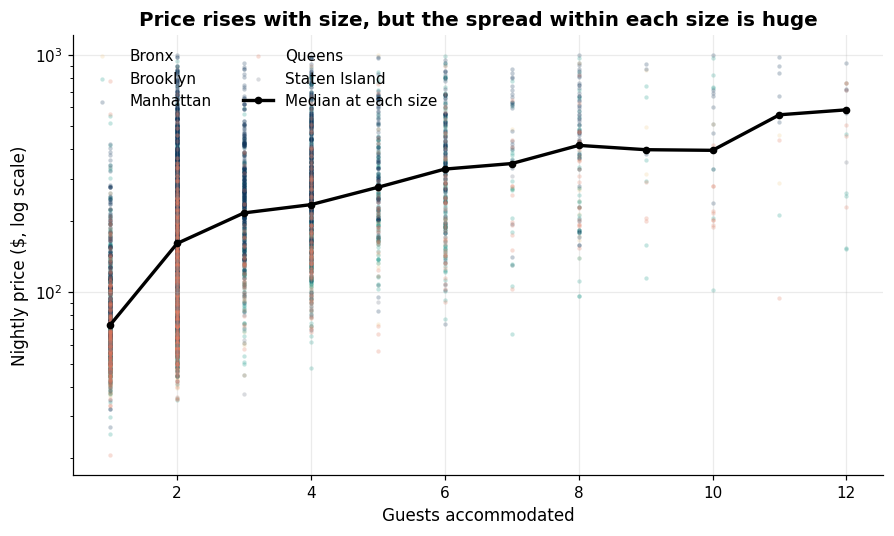

In [11]:
plot_df = clean[clean["accommodates"] <= 12].sample(6000, random_state=42)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = {"Manhattan": NAVY, "Brooklyn": TEAL, "Queens": ORANGE,
          "Bronx": GOLD, "Staten Island": GRAY}
for borough, group in plot_df.groupby("neighbourhood_group_cleansed"):
    ax.scatter(group["accommodates"], group["price"], s=8, alpha=0.25,
               color=colors[borough], label=borough, linewidths=0)

median_curve = clean[clean["accommodates"] <= 12].groupby("accommodates")["price"].median()
ax.plot(median_curve.index, median_curve.values, color="black", lw=2.2,
        marker="o", ms=4, label="Median at each size")
ax.set_yscale("log")
ax.set_xlabel("Guests accommodated")
ax.set_ylabel("Nightly price ($, log scale)")
ax.set_title("Price rises with size, but the spread within each size is huge")
ax.legend(frameon=False, ncol=2, loc="upper left")
plt.show()

Two things are true at once. The median line rises steadily — going from 2 to 4 guests roughly
moves the median from $160 to $234 — but at any given size there is a wide vertical spread. A
4-guest listing can cost $100 or $600 depending on where it is and what it is. That spread is the
space the location variable is trying to explain.

The median curve also flattens after about 6–8 guests. Adding capacity beyond that is not
associated with the same proportional price increase, which is why a linear model on raw
`accommodates` is only an approximation.

### 6.4 Location as a map

Borough medians are coarse. The same city contains very different micro-markets: the West Village
and East Harlem are both Manhattan, but they are not the same product. A scatter of longitude and
latitude coloured by log price shows whether the expensive areas form a spatial cluster.

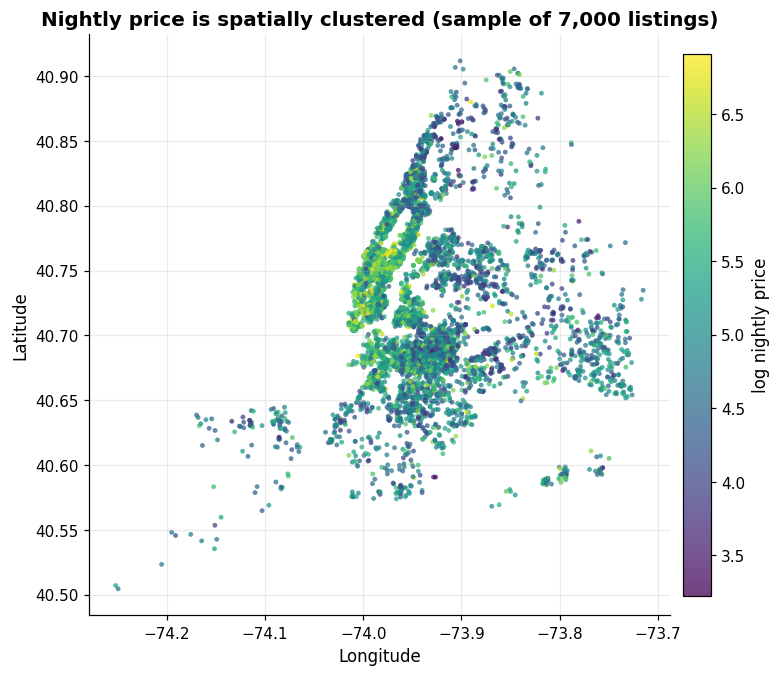

In [12]:
map_df = clean.dropna(subset=["latitude", "longitude"]).sample(7000, random_state=7)

fig, ax = plt.subplots(figsize=(8.2, 7.8))
sc = ax.scatter(map_df["longitude"], map_df["latitude"], c=map_df["log_price"],
                cmap="viridis", s=10, alpha=0.75, linewidths=0)
ax.set_aspect(1.32)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Nightly price is spatially clustered (sample of 7,000 listings)")
cbar = fig.colorbar(sc, ax=ax, shrink=0.82, pad=0.02)
cbar.set_label("log nightly price")
plt.show()

The expensive listings concentrate in lower and mid-Manhattan and along the Brooklyn waterfront;
cheaper listings cluster farther out. The pattern is not a simple radius from Times Square — there
are expensive pockets and cheap pockets close together — but it is clearly spatial. This is the
visual justification for adding a neighbourhood variable rather than only a borough variable.

### 6.5 Which neighbourhoods are expensive?

I compute the median price by neighbourhood and keep only neighbourhoods with at least 100
listings, so the ranking is not driven by one or two records. This is descriptive, not a causal
estimate: neighbourhoods differ in housing stock, room type, and listing quality as well as
location.

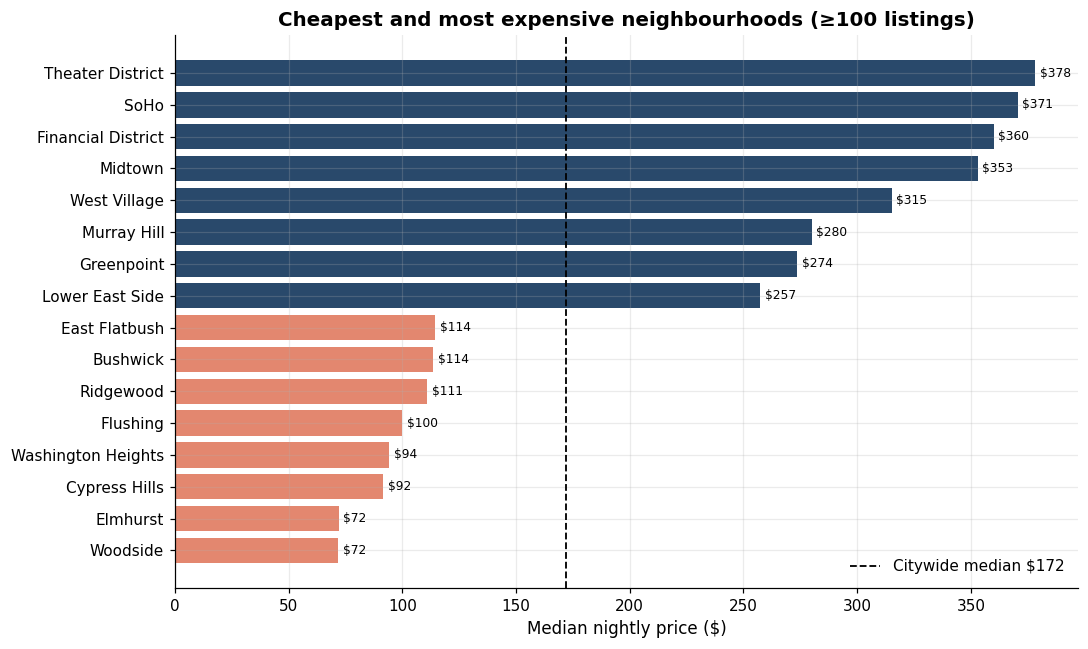

In [13]:
nbhd = (
    clean.groupby("neighbourhood_cleansed")["price"]
         .agg(["size", "median"])
         .query("size >= 100")
         .sort_values("median")
)
city_median = clean["price"].median()
selected = pd.concat([nbhd.head(8), nbhd.tail(8)])

fig, ax = plt.subplots(figsize=(10, 6))
colors_bar = [ORANGE if v < city_median else NAVY for v in selected["median"]]
bars = ax.barh(selected.index, selected["median"], color=colors_bar, alpha=0.9)
ax.axvline(city_median, color="black", ls="--", lw=1.2,
           label=f"Citywide median ${city_median:,.0f}")
ax.bar_label(bars, fmt="$%.0f", padding=3, fontsize=8)
ax.set_xlabel("Median nightly price ($)")
ax.set_title("Cheapest and most expensive neighbourhoods (≥100 listings)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

The spread is roughly 5×: Woodside and Elmhurst sit below $75, while the Theater District and SoHo
are around $370–$380. Notice that some of the expensive neighbourhoods are small (Theater District
has about 274 listings; SoHo about 128), so the ranking is directional, not precise. The point is
that "Manhattan" is too coarse a variable: the within-borough variation is as large as the
between-borough variation.

### 6.6 Correlations among the numeric variables

Before fitting anything, I check the correlation matrix for two reasons: to see which variables are
even worth including, and to spot pairs that are so correlated that their coefficients will be
unstable (multicollinearity).

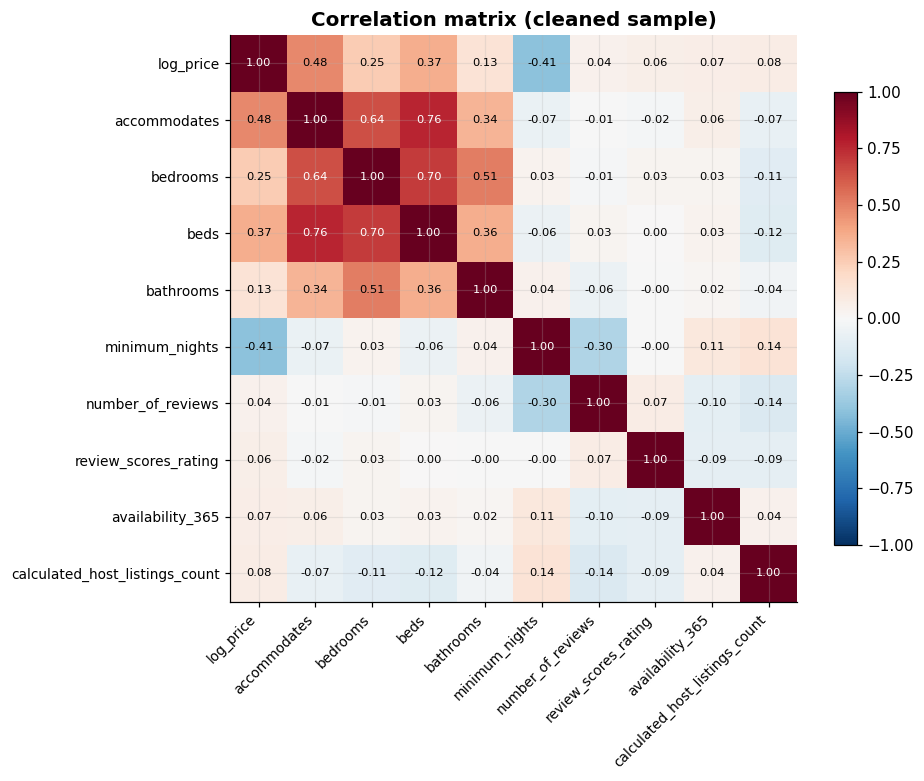

In [14]:
numeric_cols = [
    "log_price", "accommodates", "bedrooms", "beds", "bathrooms",
    "minimum_nights", "number_of_reviews", "review_scores_rating",
    "availability_365", "calculated_host_listings_count",
]
corr = clean[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(numeric_cols, fontsize=9)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                fontsize=7.5, color="white" if abs(corr.iloc[i, j]) > 0.55 else "black")
ax.set_title("Correlation matrix (cleaned sample)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

`accommodates` has the strongest correlation with log price among the size variables (0.48), and it
is also strongly correlated with `bedrooms`, `beds`, and `bathrooms`. That is expected — they are
different measurements of the same underlying size — and it is why I should not read their
coefficients as independent causal effects. Review scores and availability are only weakly
correlated with price; they may matter for booking probability, but they are not the main price
driver here.

## 7. Modelling: baseline, then comparisons

### 7.1 What I am comparing

The question is "size or location?", so I fit models that isolate each:

| Model | Features | Purpose |
|---|---|---|
| Median baseline | none | The floor any model must beat |
| Size only | accommodates, bedrooms, beds, bathrooms | How far size alone gets us |
| Size + room type | size + room type | Size with a product control |
| Location only | neighbourhood | How far location alone gets us |
| Location + room type | location + room type | Location with a product control |
| Size + location | both | The two main explanations together |
| Full | both + room type | The model I would actually use |

All models are ordinary least squares on `log(price)`. I standardise nothing: the size variables
are already in interpretable units (guests, bedrooms), and one-hot location dummies do not need
scaling. Numeric missing values are imputed with the median **inside the pipeline**, so the
imputation is fitted on the training fold only and does not leak test information.

### 7.2 Why cross-validation

A single 80/20 split gives one estimate of performance, and that estimate has variance: with 20,320
rows the holdout is 4,064 rows, which is large, but the split still determines which listings are
hard. I report 5-fold cross-validation on the full cleaned sample as the primary comparison, and the
holdout as a secondary check. When the two disagree, I trust the CV number more because it averages
over five different train/test splits.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder

SIZE = ["accommodates", "bedrooms", "beds", "bathrooms"]
LOCATION = ["neighbourhood_cleansed"]
ROOM = ["room_type"]


def make_model(num_cols, cat_cols):
    """OLS with median imputation for numerics and one-hot encoding for categories."""
    preprocess = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore", min_frequency=20),
        ), cat_cols),
    ])
    return make_pipeline(preprocess, LinearRegression())


def evaluate(name, num_cols, cat_cols):
    cols = num_cols + cat_cols
    X, y = clean[cols], clean["log_price"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    if name == "Median baseline":
        model = DummyRegressor(strategy="median")
    else:
        model = make_model(num_cols, cat_cols)

    model.fit(X_train, y_train)
    pred_log = model.predict(X_test)
    cv_r2 = cross_val_score(
        model, X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2"
    ).mean()

    # Back-transform for dollar errors. The target is log(price), so exp() is the
    # inverse. (log1p/expm1 would be the inverse pair if I had used log1p.)
    pred_dollars = np.exp(pred_log)
    actual_dollars = np.exp(y_test)

    return {
        "model": name,
        "features": len(cols),
        "cv_r2": cv_r2,
        "holdout_r2": r2_score(y_test, pred_log),
        "holdout_mae": mean_absolute_error(actual_dollars, pred_dollars),
    }


specs = [
    ("Median baseline", ["accommodates"], []),
    ("Size only", SIZE, []),
    ("Size + room type", SIZE, ROOM),
    ("Location only", [], LOCATION),
    ("Location + room type", [], LOCATION + ROOM),
    ("Size + location", SIZE, LOCATION),
    ("Full", SIZE, LOCATION + ROOM),
]

results = pd.DataFrame([evaluate(*spec) for spec in specs]).set_index("model")
results["holdout_mae"] = results["holdout_mae"].map(lambda x: f"${x:,.0f}")
results.round(3)

,features,cv_r2,holdout_r2,holdout_mae
model,,,,
Median baseline,1,-0.00,-0.00,$126
Size only,4,0.23,0.24,$114
Size + room type,5,0.32,0.33,$107
Location only,1,0.27,0.25,$108
Location + room type,2,0.38,0.38,$102
Size + location,5,0.47,0.47,$94
Full,6,0.49,0.50,$92


### 7.3 Reading the comparison

The median baseline has R² ≈ 0 by construction: predicting the same number for every listing
explains none of the variation. That is the correct floor, and it makes the other R² values
interpretable as "share of variation explained relative to knowing nothing".

The key numbers:

- **Size only: CV R² 0.234.** Size is real and useful, but it leaves most of the variation
  unexplained.
- **Location only: CV R² 0.265.** Location alone is slightly stronger than size alone.
- **Size + location: CV R² 0.469.** The two together roughly double the explanatory power of
  either alone. They are not substitutes; they are complements.
- **Full (adds room type): CV R² 0.495.** Room type adds another 0.026, because "entire home" vs
  "private room" captures a product difference that neither size nor neighbourhood fully encodes.

The incremental comparison is the cleanest answer to the question:

- Starting from **size + room type** (CV R² 0.320), adding location lifts R² to 0.495: **+0.175**.
- Starting from **location + room type** (CV R² 0.380), adding size lifts R² to 0.495: **+0.115**.

Both levers matter, and location is somewhat stronger. A useful way to say it: **size sets the
baseline, location sets the multiplier.** A 4-guest apartment is expected to cost more than a
2-guest one, but the same 4-guest apartment can double in price depending on where it is.

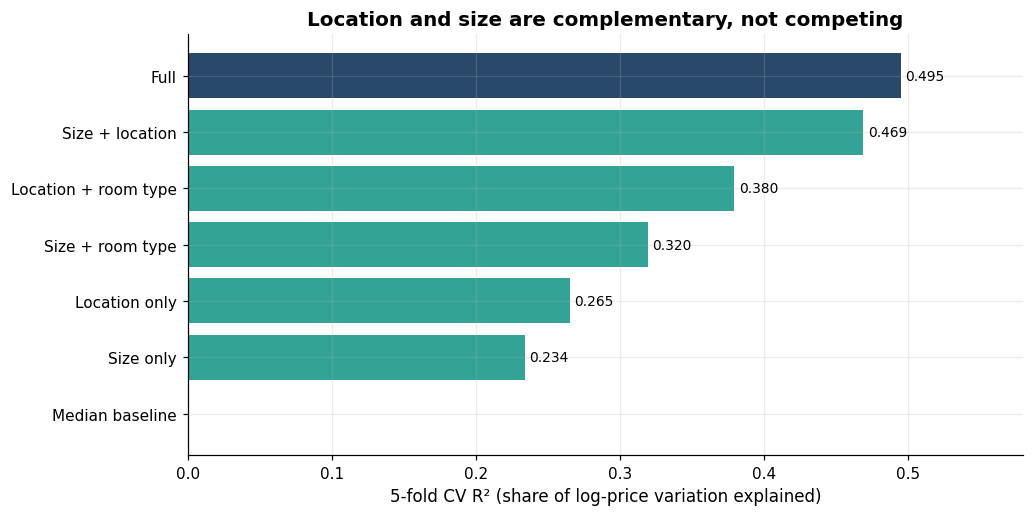

In [16]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ordered = results.sort_values("cv_r2")
bars = ax.barh(ordered.index, ordered["cv_r2"], color=[TEAL if i != "Full" else NAVY
                                                       for i in ordered.index], alpha=0.9)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set_xlabel("5-fold CV R² (share of log-price variation explained)")
ax.set_title("Location and size are complementary, not competing")
ax.set_xlim(0, 0.58)
plt.tight_layout()
plt.show()

### 7.4 What the coefficients say

For the full model, the numeric coefficients are on the log scale. A coefficient of 0.112 for
`accommodates` means that one additional guest is associated with roughly a 11.9% higher nightly
price (`exp(0.112) - 1`), holding the other included variables constant. That "holding constant" is
doing a lot of work here: because bedrooms and beds are correlated with accommodates, the
individual coefficients are not clean causal effects. They are best read as the model's internal
weights, not as "add a bed, earn 3.2% more".

I also show descriptive neighbourhood premiums — median price relative to the citywide median —
because they are easier to interpret than a long list of one-hot coefficients and they do not
require the model's linearity assumption.

In [17]:
full_model = make_model(SIZE, LOCATION + ROOM)
X_full = clean[SIZE + LOCATION + ROOM]
y_full = clean["log_price"]
full_model.fit(X_full, y_full)

feature_names = full_model.named_steps["columntransformer"].get_feature_names_out()
coefs = pd.Series(
    full_model.named_steps["linearregression"].coef_,
    index=feature_names,
)

size_effects = coefs[[f"num__{c}" for c in SIZE]].copy()
size_effects = pd.DataFrame({
    "coefficient (log points)": size_effects,
    "approx. % change per unit": (np.exp(size_effects) - 1) * 100,
})
size_effects.index = [i.replace("num__", "") for i in size_effects.index]
size_effects.round(3)

,coefficient (log points),approx. % change per unit
accommodates,0.11,11.86
bedrooms,0.08,8.02
beds,0.03,3.17
bathrooms,0.00,0.29


In [18]:
nbhd_premium = (
    clean.groupby("neighbourhood_cleansed")["price"]
         .agg(["size", "median"])
         .query("size >= 100")
)
nbhd_premium["premium_vs_city"] = nbhd_premium["median"] / city_median - 1
nbhd_premium = nbhd_premium.sort_values("premium_vs_city")

top_bottom = pd.concat([nbhd_premium.head(6), nbhd_premium.tail(6)])
top_bottom["median"] = top_bottom["median"].map(lambda x: f"${x:,.0f}")
top_bottom["premium_vs_city"] = top_bottom["premium_vs_city"].map(lambda x: f"{x:+.0%}")
top_bottom

,size,median,premium_vs_city
neighbourhood_cleansed,,,
Woodside,166,$72,-58%
Elmhurst,158,$72,-58%
Cypress Hills,141,$92,-47%
Washington Heights,254,$94,-45%
Flushing,244,$100,-42%
Ridgewood,165,$111,-35%
Murray Hill,325,$280,+63%
West Village,154,$315,+83%
Midtown,1230,$353,+105%


The premium table is descriptive, not model-adjusted: it compares raw medians, so it mixes location
with room type and size. That is why the Theatre District and SoHo look so strong — they contain a
lot of entire homes and hotel rooms. The regression partially adjusts for those factors, but it
still cannot separate "this neighbourhood is desirable" from "this neighbourhood has a different
housing stock". That distinction would need a richer dataset (within-listing price changes over
time, or a boundary-discontinuity design).

### 7.5 Residuals and error by borough

A model can have a respectable R² and still be systematically wrong in one part of the market. I
check residuals against predictions, and I break the absolute percentage error down by borough.

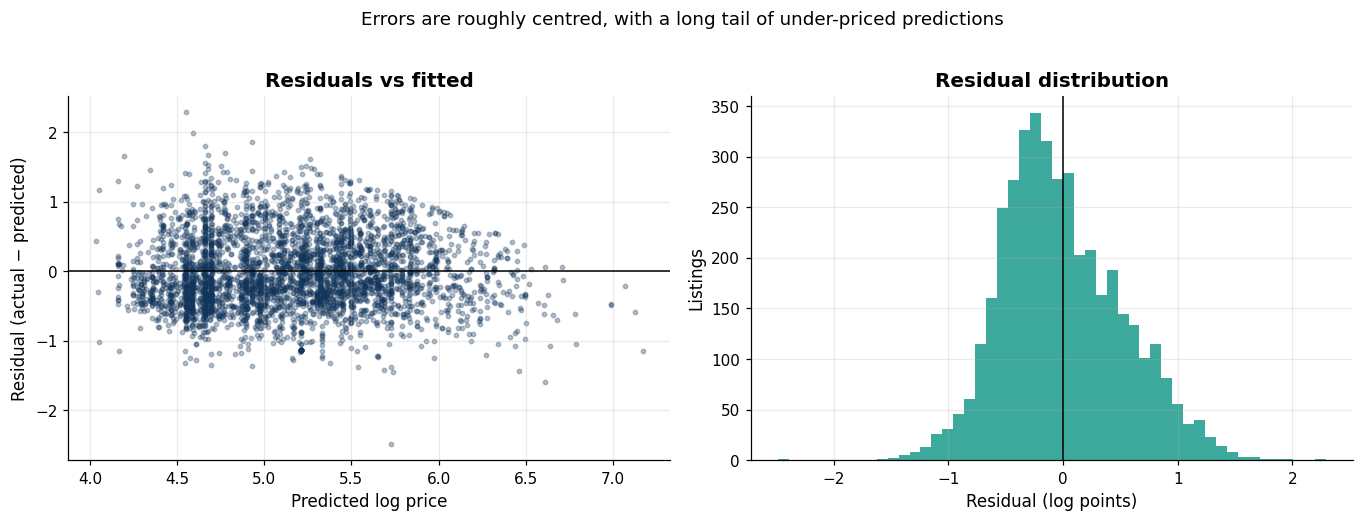

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)
full_model.fit(X_train, y_train)
pred_log = full_model.predict(X_test)
residual = y_test - pred_log

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].scatter(pred_log, residual, s=8, alpha=0.30, color=NAVY)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("Predicted log price")
axes[0].set_ylabel("Residual (actual − predicted)")
axes[0].set_title("Residuals vs fitted")

axes[1].hist(residual, bins=50, color=TEAL, alpha=0.85)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_xlabel("Residual (log points)")
axes[1].set_ylabel("Listings")
axes[1].set_title("Residual distribution")

fig.suptitle("Errors are roughly centred, with a long tail of under-priced predictions", y=1.02)
plt.tight_layout()
plt.show()

In [20]:
actual = np.exp(y_test)
pred = np.exp(pred_log)
ape = np.abs(actual - pred) / actual

print(f"Holdout MAE:                 ${np.abs(pred - actual).mean():,.2f}")
print(f"Median absolute % error:     {np.median(ape):.1%}")
print(f"Predictions within 25%:       {(ape < 0.25).mean():.1%}")
print(f"Predictions within 50%:       {(ape < 0.50).mean():.1%}")

error_by_borough = (
    pd.DataFrame({
        "borough": clean.loc[X_test.index, "neighbourhood_group_cleansed"],
        "ape": ape,
        "signed_error": pred - actual,
    })
    .groupby("borough")
    .agg(
        listings=("ape", "size"),
        median_ape=("ape", "median"),
        mae=("signed_error", lambda s: np.abs(s).mean()),
    )
    .sort_values("median_ape")
)
error_by_borough["median_ape"] = error_by_borough["median_ape"].map(lambda x: f"{x:.1%}")
error_by_borough["mae"] = error_by_borough["mae"].map(lambda x: f"${x:,.0f}")
error_by_borough

Holdout MAE:                 $92.45
Median absolute % error:     36.6%
Predictions within 25%:       34.4%
Predictions within 50%:       66.3%


,listings,median_ape,mae
borough,,,
Queens,699,34.4%,$65
Staten Island,64,34.6%,$61
Manhattan,1774,34.7%,$114
Bronx,164,39.2%,$52
Brooklyn,1363,40.4%,$84


The residual distribution is centred near zero but is right-skewed: the positive tail is longer,
meaning the model under-predicts the most expensive listings by more than it over-predicts cheap
ones. It under-predicts about 44% of listings and over-predicts about 56%, but the under-predictions
are larger. That is typical when the target is skewed and the model is fitted by least squares. The borough breakdown shows that errors are not uniform — the
median absolute percentage error is in the 30–40% range, and the dollar MAE is much larger in
Manhattan simply because prices there are larger.

This is a good place to be honest about what the model is for. If the goal is "which lever matters
more?", the model is informative. If the goal is "price my listing to within 10%", it is not good
enough — a 36.6% median error is too wide for that decision.

## 8. Evaluation in plain language

**R² = 0.495 (CV).** About half of the variation in log nightly price is explained by size,
neighbourhood, and room type. The other half is things this dataset does not contain: amenities,
condition, photos, reviews, host reputation, exact address, seasonality, and the fact that the
"price" is an asking price rather than a transaction price.

**MAE = $92.** On the holdout set, the average absolute error is about $92 per night. With a median
price of $172, that is a large error in relative terms. The median absolute percentage error is
**36.6%**, and only **34.4%** of predictions land within 25% of the actual price. Those numbers are
useful context: the model ranks drivers better than it prices individual listings.

**Why not raw price?** A model on raw price would be dominated by the expensive tail and would have
a misleadingly high R² in dollar terms. Log price makes the errors comparable across the price
range, which is the right choice when the question is about proportional differences.

**What the answer is, in one sentence:** location and size both drive price, location is slightly
stronger on its own, and they are complementary — size tells you what the listing *is*, location
tells you what the *market* will pay for it.

## 9. Limitations and next steps

**Selection bias.** 29% of listings have no price, and the missing rate varies by borough and room
type. The cleaned sample is not a random sample of the marketplace. A more careful analysis would
model the missingness explicitly or compare the visible-price sample against listing counts.

**Asking price, not transaction price.** Inside Airbnb reports the advertised nightly rate. Actual
bookings may be discounted, and occupancy is not observed here. A price model on advertised rates
answers "what do hosts ask?", not "what do guests pay?".

**No amenities or quality controls.** The dataset has an `amenities` text field, but I did not
parse it. Amenities (pool, gym, elevator, parking) and condition are likely part of the 50%
unexplained variation. Parsing the amenities list into binary features would be the single
highest-value next step.

**Linearity.** The model assumes additive effects on the log scale: each extra guest adds the same
percentage everywhere. That is an approximation. A gradient-boosted model or a model with
interactions (size × borough) would relax it, at the cost of interpretability. If I did that, I
would compare it against this linear baseline, not replace it blindly.

**Neighbourhood as a category.** The model treats each neighbourhood as a separate intercept, which
is flexible but data-hungry and ignores spatial smoothness. A spatial model (e.g. a Gaussian process
or a smoothed price surface) would share information across adjacent neighbourhoods.

**One snapshot.** This is a single scrape. Prices move with season and with regulation. A
time-series of scrapes would let me separate location effects from market-wide changes.

**Causality.** Nothing here is causal. "Location is associated with a higher price" is not the same
as "moving a listing to Manhattan would raise its price by X%". The latter would require a natural
experiment or a controlled design.

## 10. References

- Inside Airbnb, *Get the data*: https://insideairbnb.com/get-the-data/
- Inside Airbnb, *Data policies*: https://insideairbnb.com/data-policies/
- scikit-learn, *Preprocessing data* (OneHotEncoder, SimpleImputer):
  https://scikit-learn.org/stable/modules/preprocessing.html
- scikit-learn, *Cross-validation*: https://scikit-learn.org/stable/modules/cross_validation.html
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* — not used here, but the
  train/test discipline and the "baseline first" habit come from the same tradition.

---

*Reproduce: `pip install -r ../requirements.txt`, place `listings.csv.gz` in `data/`, then run the
notebook top to bottom. Runtime is about 20–40 seconds on a laptop.*